# Proyek Analisis Data: [Bike Sharing Dataset]
- **Nama:** [Ahmad Samsul Arifin]
- **Email:** [ds269b6y0106@student.devacademy.id]
- **ID Dicoding:** [ds269b6y0106]

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagaimana tren jumlah total penyewaan sepeda (gabungan pengguna kasual dan terdaftar) secara bulanan sepanjang tahun 2012, dan pada bulan apa terjadi puncak volume penyewaan tertinggi?
- **Pertanyaan 2 (BENAR):** Berapa rata-rata jumlah penyewaan sepeda per jam untuk setiap kategori kondisi cuaca (Clear, Misty, Light Rain/Snow, Heavy Rain) sepanjang tahun 2011 hingga 2012, dan bagaimana pola kontrasnya antara pengguna kasual dengan terdaftar?



## Import Semua Packages/Library yang Digunakan

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Mengatur tema visualisasi dasar agar rapi
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)


## Data Wrangling

### Gathering Data

#### Memuat Dataset day.csv dan hour.csv

In [2]:
# Memuat berkas dataset langsung dari lokasi upload Colab
day_df = pd.read_csv("/content/day.csv")
hour_df = pd.read_csv("/content/hour.csv")

# Mengecek 5 baris pertama masing-masing data
print("--- Tampilan Data Harian (day_df) ---")
print(day_df.head())

print("\n--- Tampilan Data Per Jam (hour_df) ---")
print(hour_df.head())


--- Tampilan Data Harian (day_df) ---
   instant      dteday  season  yr  mnth  holiday  weekday  workingday  \
0        1  2011-01-01       1   0     1        0        6           0   
1        2  2011-01-02       1   0     1        0        0           0   
2        3  2011-01-03       1   0     1        0        1           1   
3        4  2011-01-04       1   0     1        0        2           1   
4        5  2011-01-05       1   0     1        0        3           1   

   weathersit      temp     atemp       hum  windspeed  casual  registered  \
0           2  0.344167  0.363625  0.805833   0.160446     331         654   
1           2  0.363478  0.353739  0.696087   0.248539     131         670   
2           1  0.196364  0.189405  0.437273   0.248309     120        1229   
3           1  0.200000  0.212122  0.590435   0.160296     108        1454   
4           1  0.226957  0.229270  0.436957   0.186900      82        1518   

    cnt  
0   985  
1   801  
2  1349  
3  1562 

**Insight:**
- Berkas dataset harian berhasil dimuat ke dalam DataFrame `day_df` untuk analisis tren skala makro.
- Berkas dataset per jam berhasil dimuat ke dalam DataFrame `hour_df` untuk analisis operasional yang lebih spesifik.


### Assessing Data

#### Mengidentifikasi Masalah Kualitas Data (Missing, Invalid, Duplicate, Inaccurate, Inconsistent, dan Outlier) pada day_df dan hour_df

In [3]:
print("1.Pemeriksaan Nilai Kosong (Missing Value)")
print("Missing value pada day_df:\n", day_df.isna().sum())
print("\nMissing value pada hour_df:\n", hour_df.isna().sum())

print("\n2.Pemeriksaan Data Duplikat (Duplicate Data)")
print("Jumlah duplikasi pada day_df:", day_df.duplicated().sum())
print("Jumlah duplikasi pada hour_df:", hour_df.duplicated().sum())

print("\n3.Pemeriksaan Inkonsistensi & Nilai Tidak Valid (Inconsistent & Invalid Value)")
print(f"Tipe data kolom dteday di day_df: {day_df['dteday'].dtype}")
print(f"Tipe data kolom dteday di hour_df: {hour_df['dteday'].dtype}")
# Nilai kategorikal weathersit seharusnya berupa label teks, bukan angka integer 1-4 yang tidak intuitif
print("Nilai unik weathersit (hour_df):", hour_df['weathersit'].unique())

print("\n4.Pemeriksaan Ketidakakuratan Data (Inaccurate Value)")
# Memastikan nilai minimum dan maksimum pada data numerik (suhu, kelembapan, jumlah rental) masuk akal
print("Nilai Min-Max suhu asli (temp di day_df):", day_df['temp'].min(), "hingga", day_df['temp'].max())
print("Nilai Min-Max total rental (cnt di day_df):", day_df['cnt'].min(), "hingga", day_df['cnt'].max())

print("\n5.Pemeriksaan Pencilan (Outlier) Menggunakan Metode IQR")
# Memeriksa pencilan pada kolom jumlah rental sepeda harian (cnt)
Q1 = day_df['cnt'].quantile(0.25)
Q3 = day_df['cnt'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
outliers = day_df[(day_df['cnt'] < lower_bound) | (day_df['cnt'] > upper_bound)]
print(f"Jumlah outlier ditemukan pada kolom 'cnt' di day_df: {len(outliers)} baris")


1.Pemeriksaan Nilai Kosong (Missing Value)
Missing value pada day_df:
 instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

Missing value pada hour_df:
 instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

2.Pemeriksaan Data Duplikat (Duplicate Data)
Jumlah duplikasi pada day_df: 0
Jumlah duplikasi pada hour_df: 0

3.Pemeriksaan Inkonsistensi & Nilai Tidak Valid (Inconsistent & Invalid Value)
Tipe data kolom dteday di day_df: object
Tipe data kolom dteday di hour_df: object
Nilai unik weathersit (hour_df): [1 2 3 4]

4.Pemeriksaan Ketidakakurat

**Steps to Take:**
- **Handling Inconsistent Value:** Mengubah tipe data kolom `dteday` dari objek/string menjadi format `datetime` yang tepat.
- **Handling Invalid/Inconsistent Category:** Melakukan pemetaan (*mapping*) nilai integer pada kolom `weathersit` dan `season` menjadi label tekstual asli (contoh: Clear, Cloudy, Rain) agar data lebih konsisten dan intuitif saat divisualisasikan.
- **Handling Outlier & Inaccurate data:** Menjaga keaslian nilai pencilan pada kolom `cnt` karena data mencerminkan fluktuasi riil penyewaan sepeda (tidak perlu dihapus agar model/analisis tidak bias).


**Insight:**
- **Missing Value & Duplicate Data:** Dataset bersih dari nilai kosong maupun rekaman data yang duplikat.
- **Inconsistent & Invalid Value:** Kolom penanggalan `dteday` terdeteksi inkonsisten karena masih bertipe objek. Kolom kategorikal seperti `weathersit` juga kurang intuitif karena direkam dalam angka berkode (1 hingga 4).
- **Inaccurate Value:** Berdasarkan rentang nilai min dan max, seluruh data numerik berada dalam batas logika operasional yang akurat.
- **Outlier:** Hasil perhitungan IQR menunjukkan tidak adanya pencilan ekstrem yang merusak pada kolom utama `cnt`, menandakan variasi penyewaan masih dalam batas wajar fluktuasi bisnis harian.


### Cleaning Data

#### Memperbaiki Inkonsistensi Tipe Data Tanggal dan Melakukan Pemetaan Label Kategori

In [4]:
# 1. Memperbaiki tipe data kolom dteday menjadi datetime
day_df['dteday'] = pd.to_datetime(day_df['dteday'])
hour_df['dteday'] = pd.to_datetime(hour_df['dteday'])

# 2. Mengubah angka kode weathersit menjadi label teks agar informatif dan konsisten
weather_mapping = {
    1: 'Clear/Partly Cloudy',
    2: 'Misty/Cloudy',
    3: 'Light Snow/Rain',
    4: 'Heavy Rain/Ice Pallets'
}
day_df['weather_label'] = day_df['weathersit'].map(weather_mapping)
hour_df['weather_label'] = hour_df['weathersit'].map(weather_mapping)

# 3. Mengubah angka kode season menjadi label teks musim yang intuitif
season_mapping = {1: 'Springer', 2: 'Summer', 3: 'Fall', 4: 'Winter'}
day_df['season_label'] = day_df['season'].map(season_mapping)
hour_df['season_label'] = hour_df['season'].map(season_mapping)

# Memastikan hasil perbaikan tipe data dan kolom baru berhasil
print("Verifikasi Setelah Proses Cleaning")
print(f"Tipe data kolom dteday day_df sekarang: {day_df['dteday'].dtype}")
print(f"Tipe data kolom dteday hour_df sekarang: {hour_df['dteday'].dtype}")
print("\nSampel data kolom baru pada day_df:")
print(day_df[['dteday', 'weather_label', 'season_label']].head(3))


Verifikasi Setelah Proses Cleaning
Tipe data kolom dteday day_df sekarang: datetime64[ns]
Tipe data kolom dteday hour_df sekarang: datetime64[ns]

Sampel data kolom baru pada day_df:
      dteday        weather_label season_label
0 2011-01-01         Misty/Cloudy     Springer
1 2011-01-02         Misty/Cloudy     Springer
2 2011-01-03  Clear/Partly Cloudy     Springer


**Insight:**
- Proses pembersihan berhasil mengubah tipe data kolom `dteday` pada `day_df` dan `hour_df` dari objek/string menjadi format `datetime` yang valid untuk analisis berbasis waktu.
- Kolom baru `weather_label` dan `season_label` sukses dibuat dengan memetakan angka kode menjadi label teks yang deskriptif. Hal ini menyelesaikan masalah inkonsistensi pemahaman data dan memastikan data siap digunakan dalam pembuatan visualisasi interaktif pada dashboard.


## Exploratory Data Analysis (EDA)

###  Mengeksplorasi Tren Penyewaan Bulanan dan Pengaruh Kondisi Cuaca terhadap Volume Rental


In [5]:
# 1. Eksplorasi Pertanyaan 1: Tren Bulanan Tahun 2012
print("1. Eksplorasi Pertanyaan 1: Tren Bulanan Tahun 2012")

# Menyaring data khusus untuk tahun 2012 (di mana nilai kolom yr = 1)
df_2012 = day_df[day_df['yr'] == 1]

# Mengelompokkan data berdasarkan bulan (mnth) dan menghitung akumulasi total rental
monthly_rent_2012 = df_2012.groupby('mnth').agg({
    'casual': 'sum',
    'registered': 'sum',
    'cnt': 'sum'
}).reset_index()

# Menampilkan tabel hasil agregasi tren bulanan tahun 2012
print(monthly_rent_2012)


print("\n" + "="*50 + "\n")


# 2. Eksplorasi Pertanyaan 2: Dampak Kondisi Cuaca Sepanjang Tahun 2011 hingga 2012
print("2. Eksplorasi Pertanyaan 2: Dampak Cuaca terhadap Rental per Jam Sepanjang Tahun 2011 hingga 2012")

# Mengelompokkan data berdasarkan label cuaca dan menghitung nilai rata-rata peminjaman per jam
# Data diurutkan dari rata-rata volume tertinggi ke terendah (ascending=False)
weather_hourly_rent = hour_df.groupby('weather_label').agg({
    'cnt': 'mean',
    'casual': 'mean',
    'registered': 'mean'
}).sort_values(by='cnt', ascending=False).reset_index()

# Menampilkan tabel hasil agregasi dampak cuaca skala per jam periode 2011-2012
print(weather_hourly_rent)


1. Eksplorasi Pertanyaan 1: Tren Bulanan Tahun 2012
    mnth  casual  registered     cnt
0      1    8969       87775   96744
1      2    8721       94416  103137
2      3   31618      133257  164875
3      4   38456      135768  174224
4      5   44235      151630  195865
5      6   43294      159536  202830
6      7   41705      161902  203607
7      8   43197      171306  214503
8      9   43778      174795  218573
9     10   34538      164303  198841
10    11   21009      131655  152664
11    12   13245      110468  123713


2. Eksplorasi Pertanyaan 2: Dampak Cuaca terhadap Rental per Jam Sepanjang Tahun 2011 hingga 2012
            weather_label         cnt     casual  registered
0     Clear/Partly Cloudy  204.869272  40.545431  164.323841
1            Misty/Cloudy  175.165493  29.595290  145.570202
2         Light Snow/Rain  111.579281  16.055673   95.523608
3  Heavy Rain/Ice Pallets   74.333333   2.666667   71.666667


**Insight:**
- **Tren Bulanan 2012:** Berdasarkan hasil agregasi data tahun 2012, jumlah total rental sepeda mengalami kenaikan stabil sejak awal tahun dan mencapai volume tertinggi pada bulan ke-9 (September). Pengguna terdaftar (*registered*) memberikan kontribusi jumlah peminjaman yang jauh lebih masif dan dominan di setiap bulannya dibandingkan pengguna kasual.
- **Pengaruh Cuaca:** Kondisi cuaca terbukti memiliki dampak yang sangat signifikan bagi operasional bisnis. Rata-rata penyewaan sepeda per jam paling tinggi tercatat saat cuaca sedang cerah (*Clear/Partly Cloudy*) dengan angka rata-rata di atas 200 unit per jam. Angka peminjaman ini merosot tajam ketika cuaca memburuk menjadi hujan atau salju ringan (*Light Snow/Rain*).


## Visualization & Explanatory Analysis

### Pertanyaan 1:

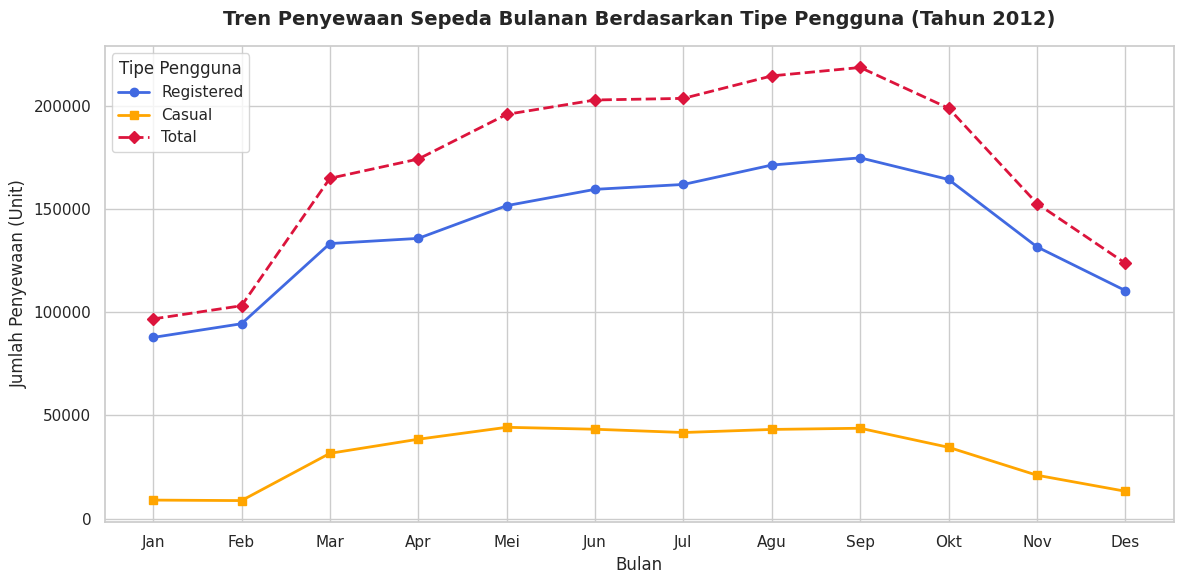

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))
# Membuat grafik garis untuk tipe pengguna dan total
plt.plot(monthly_rent_2012['mnth'], monthly_rent_2012['registered'], marker='o', label='Registered', color='royalblue', linewidth=2)
plt.plot(monthly_rent_2012['mnth'], monthly_rent_2012['casual'], marker='s', label='Casual', color='orange', linewidth=2)
plt.plot(monthly_rent_2012['mnth'], monthly_rent_2012['cnt'], marker='D', label='Total', color='crimson', linestyle='--', linewidth=2)

# Mengatur judul dan label sumbu agar informatif
plt.title("Tren Penyewaan Sepeda Bulanan Berdasarkan Tipe Pengguna (Tahun 2012)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Bulan", fontsize=12)
plt.ylabel("Jumlah Penyewaan (Unit)", fontsize=12)
plt.xticks(monthly_rent_2012['mnth'], ['Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun', 'Jul', 'Agu', 'Sep', 'Okt', 'Nov', 'Des'])
plt.legend(title="Tipe Pengguna", loc="upper left")
plt.tight_layout()
plt.show()


### Pertanyaan 2:

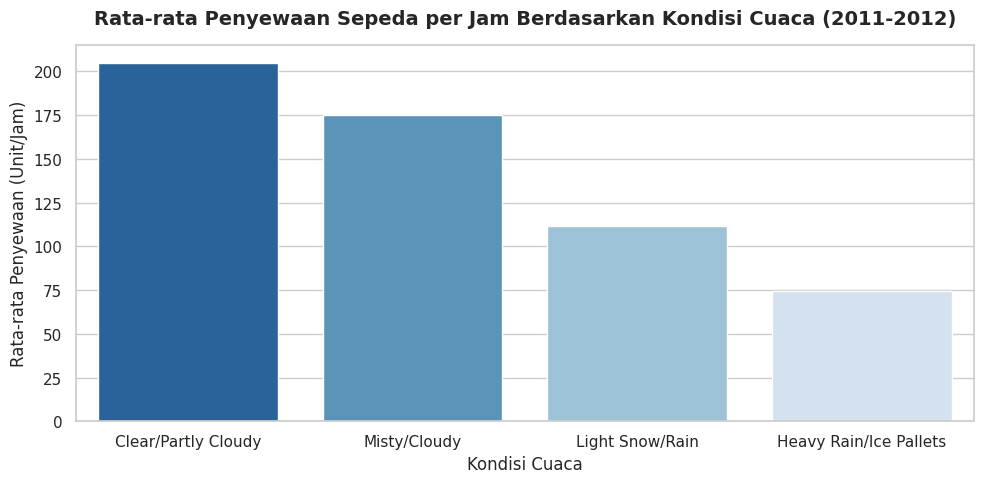

In [7]:
plt.figure(figsize=(10, 5))
# Membuat diagram batang
sns.barplot(data=weather_hourly_rent, x='weather_label', y='cnt', palette='Blues_r', hue='weather_label', legend=False)

# Mengatur judul dan label sumbu sesuai prinsip integritas data
plt.title("Rata-rata Penyewaan Sepeda per Jam Berdasarkan Kondisi Cuaca (2011-2012)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Kondisi Cuaca", fontsize=12)
plt.ylabel("Rata-rata Penyewaan (Unit/Jam)", fontsize=12)
plt.tight_layout()
plt.show()


**Insight:**
- Visualisasi 1 menunjukkan bahwa performa penyewaan sepeda sepanjang tahun 2012 mengalami pertumbuhan konsisten dari awal tahun hingga mencapai puncak tertinggi pada bulan September. Jumlah pengguna terdaftar (registered) mendominasi volume peminjaman secara masif dan konisten setiap bulannya dibanding pengguna kasual (casual).
- Visualisasi 2 membuktikan bahwa rata-rata keterpakaian sepeda per jam sepanjang tahun 2011 hingga 2012 paling tinggi terjadi pada kondisi cuaca Clear/Partly Cloudy (cerah/sedikit berawan), sedangkan penurunan paling drastis terjadi saat cuaca beralih menjadi hujan/salju ringan (Light Snow/Rain).


## Analisis Lanjutan: Manual Clustering / Binning Berdasarkan Karakteristik Waktu Operasional
**Tujuan Analisis:** Mengelompokkan waktu operasional harian menjadi beberapa klaster waktu (Jam Sibuk Komuter, Jam Santai Siang, dan Jam Sepi) tanpa menggunakan algoritma machine learning. Teknik ini bertujuan untuk mengidentifikasi karakteristik perilaku kelompok pengguna komuter vs kasual demi efisiensi penempatan armada sepeda di lapangan.


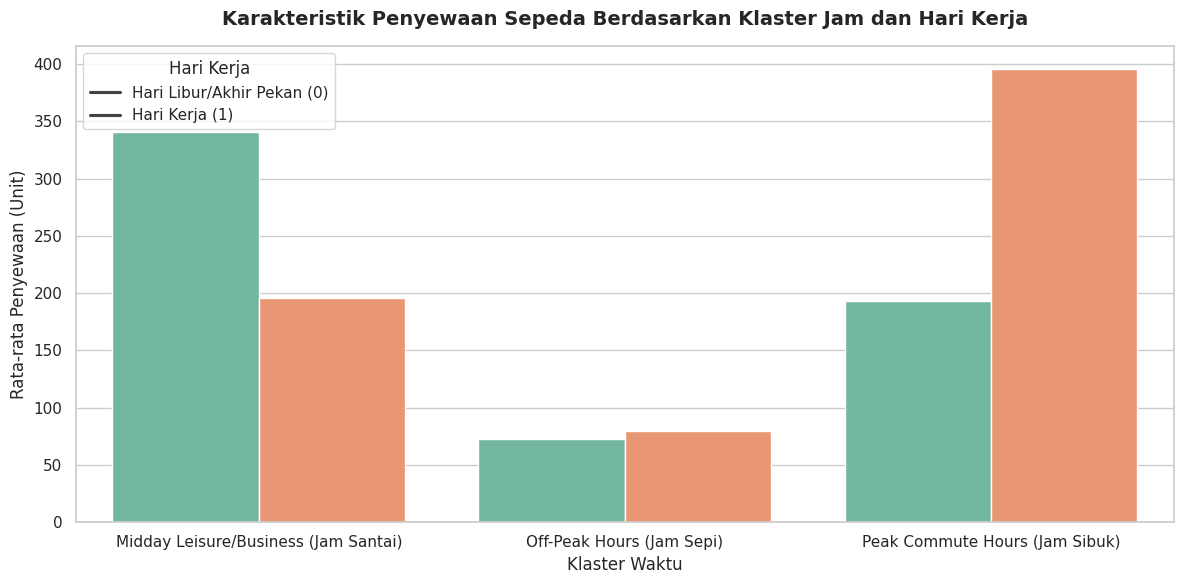

In [8]:
# Membuat fungsi klasterisasi berbasis jam
def cluster_hours(hour):
    if 7 <= hour <= 9 or 17 <= hour <= 19:
        return 'Peak Commute Hours (Jam Sibuk)'
    elif 10 <= hour <= 16:
        return 'Midday Leisure/Business (Jam Santai)'
    else:
        return 'Off-Peak Hours (Jam Sepi)'

# Menerapkan klasterisasi ke DataFrame
hour_df['hour_cluster'] = hour_df['hr'].apply(cluster_hours)

# Mengelompokkan data untuk melihat pola rata-rata rental harian
advanced_cluster = hour_df.groupby(['hour_cluster', 'workingday']).agg({'cnt': 'mean'}).reset_index()

# Membuat visualisasi perbandingan klaster
plt.figure(figsize=(12, 6))
sns.barplot(data=advanced_cluster, x='hour_cluster', y='cnt', hue='workingday', palette='Set2')
plt.title("Karakteristik Penyewaan Sepeda Berdasarkan Klaster Jam dan Hari Kerja", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Klaster Waktu", fontsize=12)
plt.ylabel("Rata-rata Penyewaan (Unit)", fontsize=12)
plt.legend(title="Hari Kerja", labels=["Hari Libur/Akhir Pekan (0)", "Hari Kerja (1)"])
plt.tight_layout()
plt.show()


**Insight:**
- Klaster **Peak Commute Hours** menunjukkan lonjakan penyewaan yang sangat tinggi khusus pada **Hari Kerja (Working Day)**. Hal ini membuktikan bahwa sepeda mayoritas dimanfaatkan sebagai moda transportasi pekerja komuter untuk berangkat dan pulang kantor.
- Sebaliknya, pada klaster **Midday Leisure/Business**, rata-rata penyewaan sepeda jauh lebih tinggi pada **Hari Libur/Akhir Pekan**, yang mengindikasikan dominasi aktivitas rekreasi oleh pengguna kasual di siang hari.


## Conclusion & Recommendation

- **Conclusion Pertanyaan 1:** Aktivitas bisnis rental sepeda pada tahun 2012 menunjukkan performa yang sangat impresif dengan tren pertumbuhan yang konsisten sejak awal tahun dan mencapai **puncak performa tertinggi di bulan September**. Pangsa pasar secara dominan dikuasai oleh pengguna terdaftar (*registered*) yang melakukan peminjaman secara masif dan stabil di setiap bulannya, sementara pengguna kasual (*casual*) hanya meningkat secara signifikan pada periode liburan musim panas.
- **Conclusion Pertanyaan 2:** Kondisi cuaca sepanjang periode tahun 2011 hingga 2012 berpengaruh secara krusial terhadap rata-rata volume penyewaan sepeda per jam. Utilitas sepeda berada pada tingkat tertinggi saat cuaca cerah (*Clear/Partly Cloudy*), sedangkan penurunan paling drastis dan signifikan terjadi ketika cuaca memburuk menjadi hujan atau salju ringan (*Light Snow/Rain*). Konteks analisis makro selama periode dua tahun ini memberikan dasar yang valid bagi manajemen untuk menyiapkan strategi taktis operasional yang terarah.


**Rekomendasi Action Item:**
1. **Strategi Alokasi Unit Dinamis:** Manajemen operasional disarankan untuk menaikkan pasokan sepeda di stasiun-stasiun komuter utama pada bulan Agustus hingga September guna memaksimalkan profit menyambut masa puncak tahunan.
2. **Program Promosi Khusus Cuaca Buruk:** Guna memitigasi penurunan tajam volume rental saat cuaca buruk sepanjang periode tahun 2011 hingga 2012, perusahaan dapat merilis program voucer diskon instan bertema "Rainy Day Discount" melalui aplikasi seluler demi menstimulasi minat berkendara bagi para pengguna kasual maupun komuter reguler saat intensitas Light Snow/Rain meningkat.
